In [ ]:
!pip install -q torchmetrics[image] scikit-image

import os
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric
import matplotlib.pyplot as plt

# 1. Penetapan Random Seed Tetap (Wajib Sesuai Panduan)
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)
print(f"Menggunakan device: {device}")

Menggunakan device: cuda


In [ ]:
# Transformasi standar ke Tensor [0, 1]
transform = transforms.Compose([
    transforms.ToTensor()
])

# Unduh dataset penuh (60.000 train + 10.000 test = 70.000 citra)
full_train_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
official_test_data = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# Gabungkan lalu bagi sesuai aturan: 80% Train (56.000), 10% Val (7.000), 10% Test (7.000)
full_dataset = torch.utils.data.ConcatDataset([full_train_data, official_test_data])
train_size = int(0.8 * len(full_dataset))
val_size = int(0.1 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

FASHION_CLASSES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Total Data: {len(full_dataset)} | Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Total Data: 70000 | Train: 56000 | Val: 7000 | Test: 7000


In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # Arsitektur sesuai panduan: 784 -> 256 -> 64 -> 10
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def extract_features(self, x):
        x = x.view(-1, 784)
        h1 = F.relu(self.fc1(x))
        z_mlp = F.relu(self.fc2(h1)) # Representasi laten z_MLP (R^64)
        return z_mlp

    def forward(self, x):
        z_mlp = self.extract_features(x)
        logits = self.fc3(z_mlp)
        return logits, z_mlp

    # Tahap 2: Proyeksi balik langsung dari vektor kelas one-hot y_c menggunakan W^T
    def transpose_from_class(self, y_onehot):
        with torch.no_grad():
            z_hat = F.relu(F.linear(y_onehot, self.fc3.weight.t()))
            h1_hat = F.relu(F.linear(z_hat, self.fc2.weight.t()))
            x_hat = torch.sigmoid(F.linear(h1_hat, self.fc1.weight.t()))
        return x_hat.view(-1, 1, 28, 28)

    # Tahap 3: Proyeksi balik langsung dari latent features z_MLP menggunakan W^T
    def transpose_from_latent(self, z_mlp):
        with torch.no_grad():
            h1_hat = F.relu(F.linear(z_mlp, self.fc2.weight.t()))
            x_hat = torch.sigmoid(F.linear(h1_hat, self.fc1.weight.t()))
        return x_hat.view(-1, 1, 28, 28)


class FrozenLatentDecoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        # Arsitektur Decoder terpisah: 64 -> 256 -> 784
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

In [ ]:
# --- TAHAP 1: Melatih MLP Classifier hingga akurasi Test >= 88% ---
mlp_clf = MLPClassifier().to(device)
optimizer_clf = torch.optim.Adam(mlp_clf.parameters(), lr=1e-3)
criterion_ce = nn.CrossEntropyLoss()

print("=== TAHAP 1: Training MLP Classifier ===")
for epoch in range(1, 16):
    mlp_clf.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer_clf.zero_grad()
        logits, _ = mlp_clf(x)
        loss = criterion_ce(logits, y)
        loss.backward()
        optimizer_clf.step()

    # Evaluasi pada Test Set
    mlp_clf.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            logits, _ = mlp_clf(x)
            preds = logits.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    acc = 100.0 * correct / total
    if epoch % 3 == 0 or acc >= 88.0:
        print(f"Epoch {epoch:02d} | Test Accuracy: {acc:.2f}%")

assert acc >= 88.0, "Akurasi belum mencapai 88%, tambah jumlah epoch!"
torch.save(mlp_clf.state_dict(), "checkpoints/mlp_classifier.pth")

# --- TAHAP 4: Melatih Frozen Latent Decoder (64 -> 256 -> 784) ---
for param in mlp_clf.parameters():
    param.requires_grad = False # Bekukan seluruh bobot MLP Classifier

frozen_decoder = FrozenLatentDecoder(latent_dim=64).to(device)
optimizer_dec = torch.optim.Adam(frozen_decoder.parameters(), lr=1e-3)
criterion_mse = nn.MSELoss()

print("\n=== TAHAP 4: Training Frozen Latent Decoder dari z_MLP ===")
for epoch in range(1, 21):
    frozen_decoder.train()
    train_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        with torch.no_grad():
            z_mlp = mlp_clf.extract_features(x)
        x_recon = frozen_decoder(z_mlp)
        loss = criterion_mse(x_recon, x)
        optimizer_dec.zero_grad()
        loss.backward()
        optimizer_dec.step()
        train_loss += loss.item() * x.size(0)
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | Train MSE: {train_loss / len(train_dataset):.6f}")

# Evaluasi Kuantitatif Frozen Latent Decoder pada Test Set (untuk dibandingkan dgn Vanilla AE)
frozen_decoder.eval()
mse_list, psnr_list, ssim_list, all_z_mlp = [], [], [], []

with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        z_mlp = mlp_clf.extract_features(x)
        all_z_mlp.append(z_mlp.cpu())
        x_recon = frozen_decoder(z_mlp)

        x_np = x.cpu().numpy()
        recon_np = x_recon.cpu().numpy()
        for i in range(x_np.shape[0]):
            orig = x_np[i, 0]
            rec = recon_np[i, 0]
            mse_list.append(np.mean((orig - rec) ** 2))
            psnr_list.append(psnr_metric(orig, rec, data_range=1.0))
            ssim_list.append(ssim_metric(orig, rec, data_range=1.0))

all_z_mlp = torch.cat(all_z_mlp, dim=0)
print(f"\n[Metrik Frozen Latent Decoder Z_MLP pada Test Set]")
print(f"Test MSE : {np.mean(mse_list):.6f}")
print(f"Test PSNR: {np.mean(psnr_list):.2f} dB")
print(f"Test SSIM: {np.mean(ssim_list):.4f}")

=== TAHAP 1: Training MLP Classifier ===
Epoch 03 | Test Accuracy: 86.40%
Epoch 06 | Test Accuracy: 87.53%
Epoch 09 | Test Accuracy: 87.50%
Epoch 10 | Test Accuracy: 88.01%
Epoch 11 | Test Accuracy: 88.17%
Epoch 12 | Test Accuracy: 88.34%
Epoch 13 | Test Accuracy: 88.70%
Epoch 14 | Test Accuracy: 88.63%
Epoch 15 | Test Accuracy: 89.06%

=== TAHAP 4: Training Frozen Latent Decoder dari z_MLP ===
Epoch 05 | Train MSE: 0.020397
Epoch 10 | Train MSE: 0.018540
Epoch 15 | Train MSE: 0.017732
Epoch 20 | Train MSE: 0.017219

[Metrik Frozen Latent Decoder Z_MLP pada Test Set]
Test MSE : 0.017591
Test PSNR: 18.27 dB
Test SSIM: 0.6500


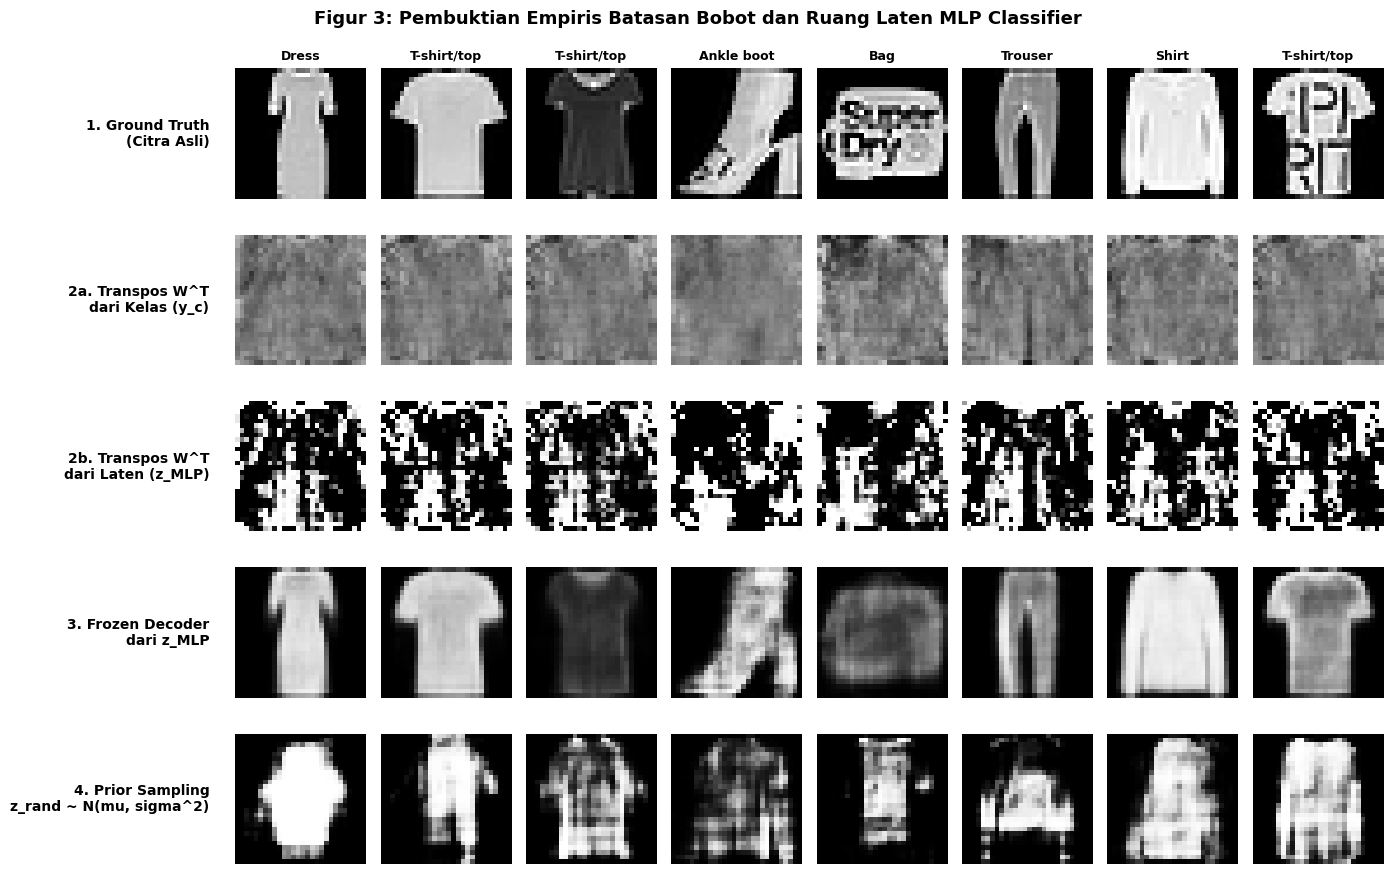

In [ ]:
# Ambil 8 sampel representatif dari Test Set
sample_x, sample_y = next(iter(test_loader))
sample_x = sample_x[:8].to(device)
sample_y = sample_y[:8].to(device)

with torch.no_grad():
    # Panel 1: Ground Truth
    gt_imgs = sample_x.cpu()

    # Panel 2a: Tahap 2 - Proyeksi balik W^T dari One-Hot Class Vector y_c
    y_onehot = F.one_hot(sample_y, num_classes=10).float()
    w_trans_class = mlp_clf.transpose_from_class(y_onehot).cpu()

    # Panel 2b: Tahap 3 - Proyeksi balik W^T dari Latent Features z_MLP
    z_sample = mlp_clf.extract_features(sample_x)
    w_trans_latent = mlp_clf.transpose_from_latent(z_sample).cpu()

    # Panel 3: Tahap 4 - Rekonstruksi Frozen Latent Decoder dari z_MLP
    frozen_recon = frozen_decoder(z_sample).cpu()

    # Panel 4: Tahap 5 - Random Prior Sampling z_rand ~ N(mu_z, diag(sigma_z^2))
    mu_z = all_z_mlp.mean(dim=0).to(device)
    std_z = all_z_mlp.std(dim=0).to(device)
    z_rand = mu_z + std_z * torch.randn(8, 64, device=device)
    rand_gen = frozen_decoder(z_rand).cpu()

# Plotting Figur 3 (Resolusi Tinggi 300 DPI)
fig, axes = plt.subplots(5, 8, figsize=(14, 9))
row_titles = [
    "1. Ground Truth\n(Citra Asli)",
    "2a. Transpos W^T\ndari Kelas (y_c)",
    "2b. Transpos W^T\ndari Laten (z_MLP)",
    "3. Frozen Decoder\ndari z_MLP",
    "4. Prior Sampling\nz_rand ~ N(mu, sigma^2)"
]

rows_data = [gt_imgs, w_trans_class, w_trans_latent, frozen_recon, rand_gen]

for r_idx, (row_imgs, title) in enumerate(zip(rows_data, row_titles)):
    for c_idx in range(8):
        ax = axes[r_idx, c_idx]
        ax.imshow(row_imgs[c_idx, 0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if r_idx == 0:
            ax.set_title(FASHION_CLASSES[sample_y[c_idx].item()], fontsize=9, fontweight="bold")
    axes[r_idx, 0].text(-0.2, 0.5, title, transform=axes[r_idx, 0].transAxes,
                        fontsize=10, fontweight="bold", va="center", ha="right")

plt.suptitle("Figur 3: Pembuktian Empiris Batasan Bobot dan Ruang Laten MLP Classifier", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("results/figur_3_mlp_proof.png", dpi=300, bbox_inches="tight")
plt.show()